# Validate linear summation (metamodel vs dynamic)

Compare offshore-driven **dynamic SnapWave** to the **reconstructed metamodel**
(bulk mode: WHACS bulk partition per goal, wavespectra linear sum).

Bulk output is configured in the case JSON → `metamodel.reconstruction.variables`
(HyGloW name → wavespectra stat). Set `save_spectra: true` to cache summed spectra
for notebook 11.

Comparison uses `hs`, `tp`, `dir`, and `spr` when both datasets contain them
(`val.resolve_comparison_variables`).

**Prerequisites:** fitted models (06), dynamic run (08). Use `recompute=True` after refitting.

In [1]:
import os
import time

os.environ["OMP_NUM_THREADS"] = "8"  # avoid oversubscription when using dask

import matplotlib.pyplot as plt
import xarray as xr
from utils import metamodel as mm
from utils import simulation as sim
from utils import validation as val

## Configuration

In [2]:
period = "2013"
offshore_name = "WHACS_cal"
mda_n = 550  # must match a fitted mda_candidates entry
mm_set = "buoys"  # metamodel set (metamodel.sets); `sites` must belong to it

# Site subset — isobath depth, mesh polygon, buoy id, or umbrella
sites = None  # e.g. "10m", "buoy", or a list of explicit site ids

# Metrics to compare (subset used when missing from either dataset)
compare_variables = ["hs", "tp", "dir", "spr"]

dynamic_path = sim.cases_dir("dynamic") / f"Dynamic_Cases_{offshore_name}_{period}.nc"

print(f"period       : {period}")
print(f"mda_n        : {mda_n}")
print(f"metamodel    : {mm_set}")
print(f"sites        : {sites}")
print(f"compare vars : {compare_variables}")
print(f"dynamic path : {dynamic_path}")

period       : 2013
mda_n        : 550
metamodel    : buoys
sites        : None
compare vars : ['hs', 'tp', 'dir', 'spr']
dynamic path : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/SnapWave_CASES_Dynamic/Dynamic_Cases_WHACS_cal_2013.nc


## 1 · Check models

In [4]:
mm.require_models(mm_set, mda_n)
print(f"sites of {mm_set!r} kept in every goal: {len(mm.reconstruction_sites(mm_set))}")

common model sites: 5148


## 2 · Reconstruct metamodel (bulk)

In [5]:
t0 = time.perf_counter()
metamodel = mm.reconstruct(
    period,
    mda_n,
    metamodel=mm_set,
    spectral=False,
    offshore_name=offshore_name,
    sites=sites,
    workers=8,
    save_spectra=False,  # bulk-vs-dynamic validation never reads spectra
    wind_correction=True,  # apply wind correction to dynamic cases
)
reconstruct_seconds = time.perf_counter() - t0
print(
    f"Reconstruction took {reconstruct_seconds:.2f}s for {metamodel.sizes.get('sites', '?')} sites"
)
metamodel

INFO:bluemath_tk.waves.hywaves.reconstruction:[group 6/8] sum batch 1/5 (1 sites) in 5.2s (5.2s elapsed)
INFO:bluemath_tk.waves.hywaves.reconstruction:[group 2/8] sum batch 1/5 (1 sites) in 5.7s (5.7s elapsed)
INFO:bluemath_tk.waves.hywaves.reconstruction:[group 4/8] sum batch 1/5 (1 sites) in 5.7s (5.7s elapsed)
INFO:bluemath_tk.waves.hywaves.reconstruction:[group 3/8] sum batch 1/5 (1 sites) in 5.7s (5.7s elapsed)
INFO:bluemath_tk.waves.hywaves.reconstruction:[group 1/8] sum batch 1/5 (1 sites) in 5.8s (5.8s elapsed)
INFO:bluemath_tk.waves.hywaves.reconstruction:[group 5/8] sum batch 1/5 (1 sites) in 5.8s (5.8s elapsed)
INFO:bluemath_tk.waves.hywaves.reconstruction:[group 7/8] sum batch 1/4 (1 sites) in 5.8s (5.8s elapsed)
INFO:bluemath_tk.waves.hywaves.reconstruction:[group 8/8] sum batch 1/4 (1 sites) in 5.5s (5.5s elapsed)
INFO:bluemath_tk.waves.hywaves.reconstruction:[group 7/8] sum batch 2/4 (1 sites) in 5.0s (10.8s elapsed)
INFO:bluemath_tk.waves.hywaves.reconstruction:[group 6

Reconstruction took 166.47s for 38 sites


<xarray.Dataset> Size: 12MB
Dimensions:             (time: 8760, sites: 38)
Coordinates:
  * time                (time) datetime64[ns] 70kB 2013-01-01 ... 2013-12-31T...
  * sites               (sites) <U30 5kB 'buoy_SchiermonnikoogNoord' ... 'buo...
    site_source         (sites) <U7 1kB 'buoy' 'buoy' 'buoy' ... 'buoy' 'buoy'
    site_label          (sites) <U8 1kB 'waves' 'waves' ... 'waves' 'waves'
    site_mesh_depth     (sites) float64 304B 20.6 8.262 26.89 ... 27.8 29.36
    site_nominal_depth  (sites) float64 304B 21.0 7.0 27.0 ... 25.0 30.0 31.0
    site_longitude      (sites) float64 304B 6.17 6.16 3.31 ... 3.742 3.43 3.28
    site_latitude       (sites) float64 304B 53.59 53.53 51.75 ... 51.98 52.0
Data variables:
    hs                  (time, sites) float64 3MB 1.508 1.432 ... 1.731 1.764
    tp                  (time, sites) float32 1MB 7.56 7.576 ... 4.794 4.85
    dir                 (time, sites) float64 3MB 258.8 262.4 ... 224.4 225.9
    spr                 (time, sites) float64 3MB 31.6 38.52 ... 28.24 27.36
    wind_k              (time, sites) float64 3MB 1.424 1.421 ... 1.522 1.471

## 3 · Load dynamic reference

In [6]:
dynamic = xr.open_dataset(dynamic_path).sel(time=period)
dynamic = dynamic.sel(sites=metamodel.sites.values).load()
dynamic

<xarray.Dataset> Size: 5MB
Dimensions:             (time: 8760, sites: 38)
Coordinates:
  * time                (time) datetime64[ns] 70kB 2013-01-01 ... 2013-12-31T...
  * sites               (sites) <U30 5kB 'buoy_A2' ... 'buoy_zdv8-2d-MMND'
    site_source         (sites) <U7 1kB 'buoy' 'buoy' 'buoy' ... 'buoy' 'buoy'
    site_label          (sites) <U8 1kB 'waves' 'waves' ... 'waves' 'waves'
    site_mesh_depth     (sites) float64 304B 10.41 9.97 22.64 ... 13.55 16.03
    site_nominal_depth  (sites) float64 304B 11.0 11.0 22.0 ... 15.0 8.0 21.0
    site_longitude      (sites) float64 304B 3.12 5.95 2.82 ... 6.367 3.42 4.01
    site_latitude       (sites) float64 304B 51.36 53.5 51.42 ... 51.43 51.99
Data variables:
    hs                  (time, sites) float32 1MB 1.537 1.162 ... 0.7322 1.132
    tp                  (time, sites) float32 1MB 6.402 6.713 ... 5.706 6.403
    dir                 (time, sites) float32 1MB 259.5 283.9 ... 229.3 240.2
    spr                 (time, sites) float32 1MB 28.67 29.41 ... 38.24 47.09
Attributes:
    Conventions:                         Conventions = 'CF-1.6, SGRID-0.3
    Build-Revision-Date-Netcdf-library:  4.9.3 of Aug 25 2026 19:35:26 $
    Producer:                            SnapWave
    title:                               Snapwave his point netcdf output

## 4 · Compare

In [7]:
variables = val.resolve_comparison_variables(
    metamodel,
    dynamic,
    variables=compare_variables,
)
print(f"Comparing: {variables}")

result = val.compare(
    reference=dynamic,
    estimate=metamodel,
    variables=variables,
    reference_label=val.DYNAMIC_REFERENCE_LABEL,
    estimate_label="Linear summation",
)
result.metrics

Comparing: ['hs', 'tp', 'dir', 'spr']


,pca_variances,group,site_source,site_label,variable,label,n,bias,rmse,rrmse,si,r,r2,reference_label,estimate_label
0,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_SchiermonnikoogNoord,buoy,waves,hs,Hs,8760,-0.090860,0.290400,0.210807,0.175229,0.933063,0.854590,Dynamic SnapWave,Linear summation
1,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_SchiermonnikoogNoord,buoy,waves,tp,Tp,8760,0.330004,1.671975,0.252584,0.241454,0.739327,-0.234476,Dynamic SnapWave,Linear summation
2,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_SchiermonnikoogNoord,buoy,waves,dir,Dir,8760,-3.329883,22.847536,NaN,NaN,NaN,0.849772,Dynamic SnapWave,Linear summation
3,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_SchiermonnikoogNoord,buoy,waves,spr,Spr,8760,0.050196,7.003713,0.233879,0.223754,0.686908,0.408570,Dynamic SnapWave,Linear summation
4,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_SchiermonnikoogWestgat,buoy,waves,hs,Hs,8760,0.023332,0.211349,0.182378,0.161142,0.946901,0.874641,Dynamic SnapWave,Linear summation
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
147,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_EurogeulE5,buoy,waves,spr,Spr,8759,-1.706361,8.348051,0.259548,0.242004,0.630365,0.340775,Dynamic SnapWave,Linear summation
148,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Europlatform,buoy,waves,hs,Hs,8760,-0.134379,0.648068,0.442413,0.368559,0.730448,0.483527,Dynamic SnapWave,Linear summation
149,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Europlatform,buoy,waves,tp,Tp,8759,-0.423830,1.777737,0.267496,0.253983,0.559205,-0.549024,Dynamic SnapWave,Linear summation
150,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Europlatform,buoy,waves,dir,Dir,8760,1.781251,23.803602,NaN,NaN,NaN,0.886291,Dynamic SnapWave,Linear summation


## 5 · Save metrics

In [8]:
metrics_out = result.metrics.copy()
metrics_out.insert(0, "period", period)
metrics_out.insert(1, "metamodel", mm_set)
metrics_out.insert(2, "mda_candidate", mda_n)
metrics_out.insert(3, "offshore_name", offshore_name)
metrics_out["n_sites"] = int(metamodel.sizes["sites"])
# Wall time for mm.reconstruct() above — near-zero if these sites/period
# were already cached from a previous run, not a fresh-simulation cost.
metrics_out["reconstruct_seconds"] = reconstruct_seconds

out_path = val.metamodel_validation_path(period, mm_set)
out_path.parent.mkdir(parents=True, exist_ok=True)
metrics_out.to_csv(out_path, index=False)
print(f"Wrote {out_path}")

Wrote /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/metamodel_validation/linear_summation_buoys_2013.csv


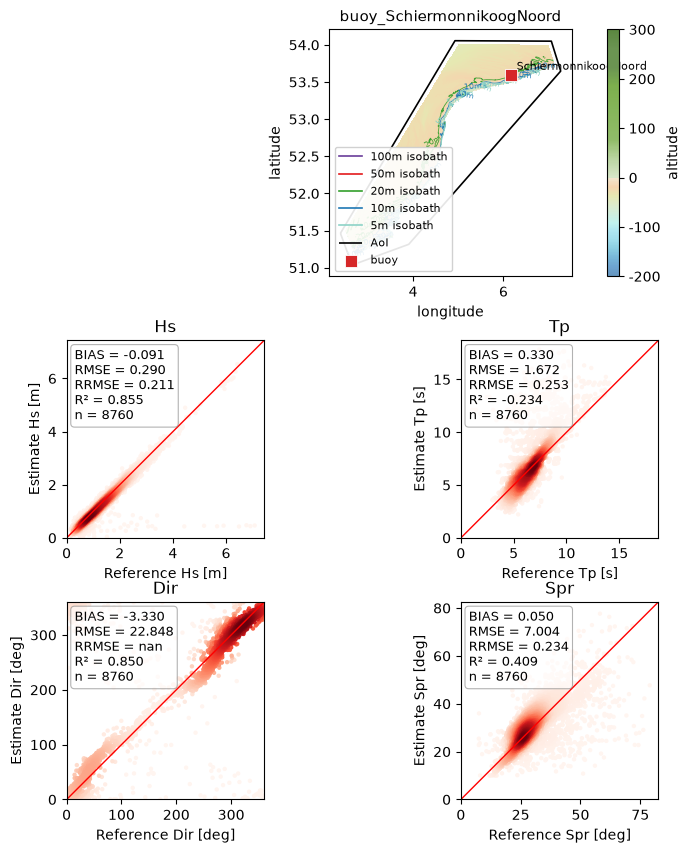

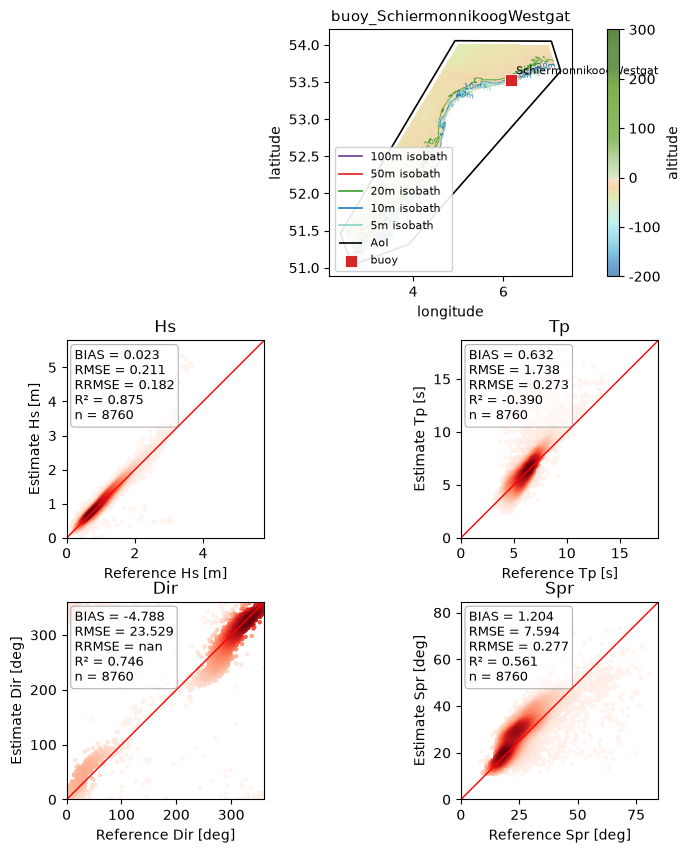

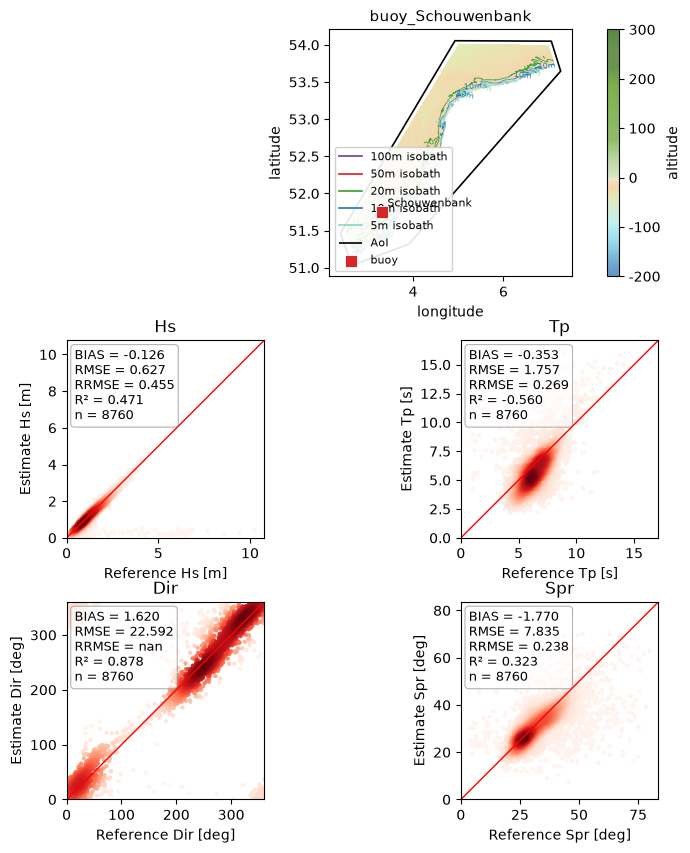

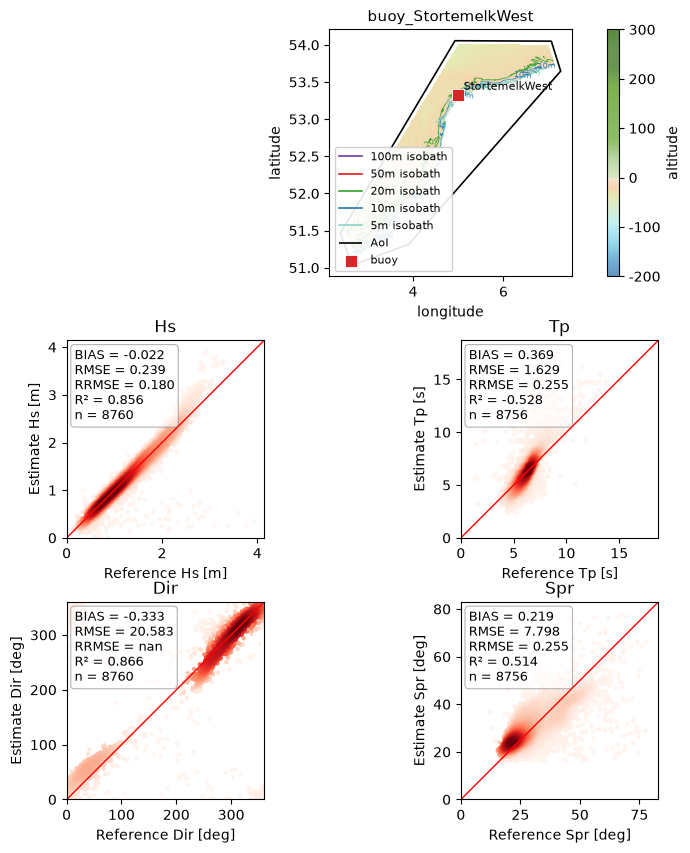

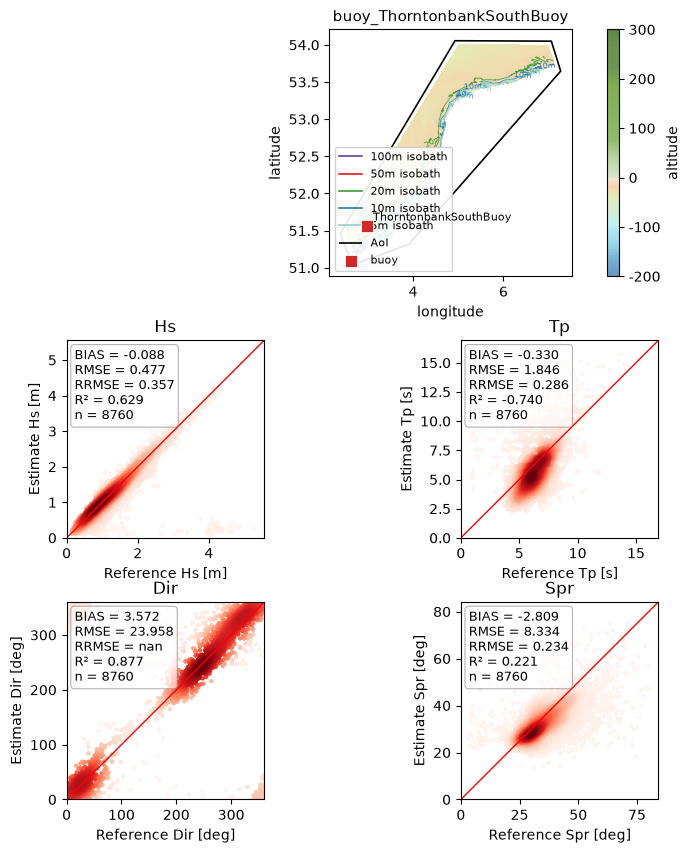

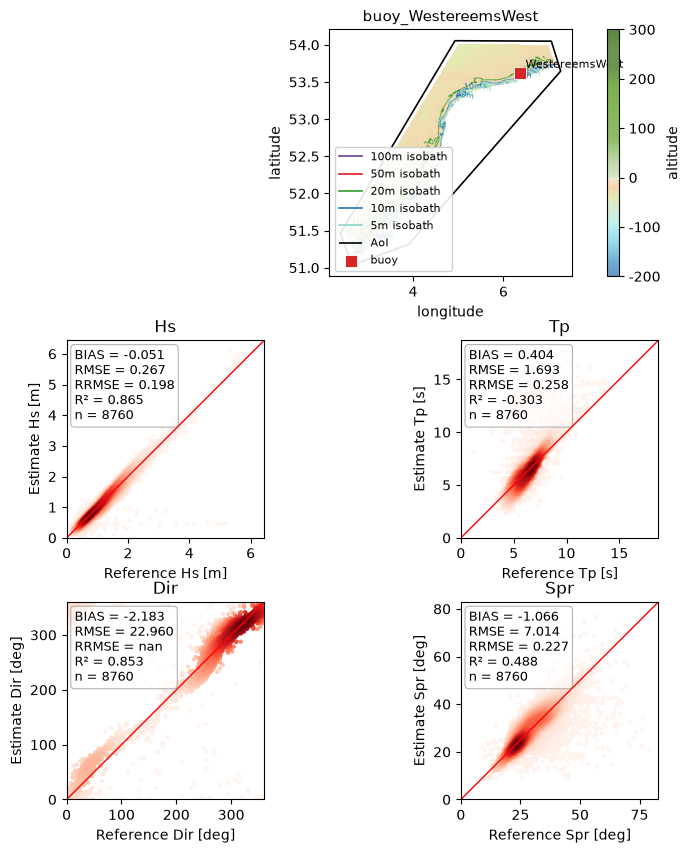

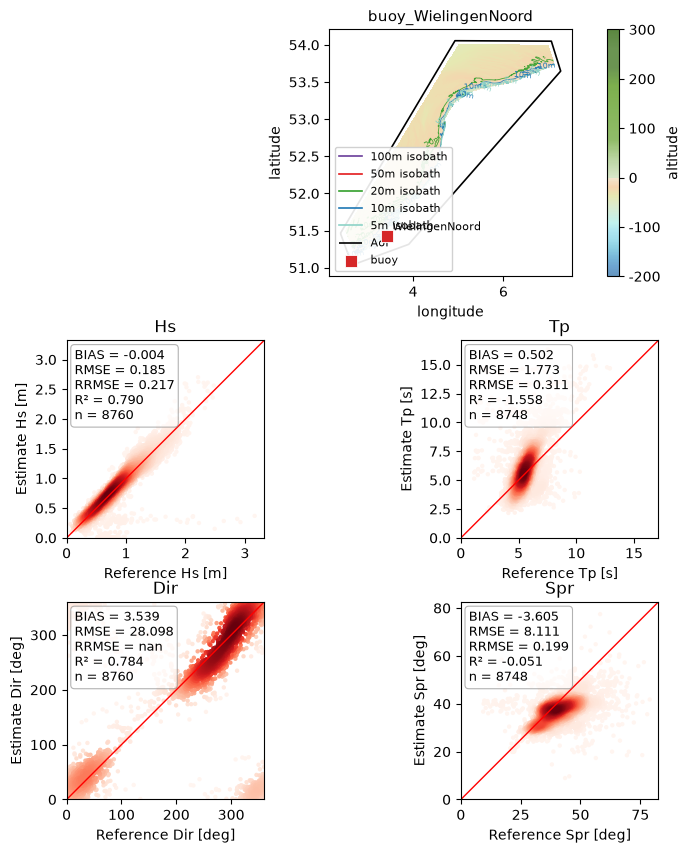

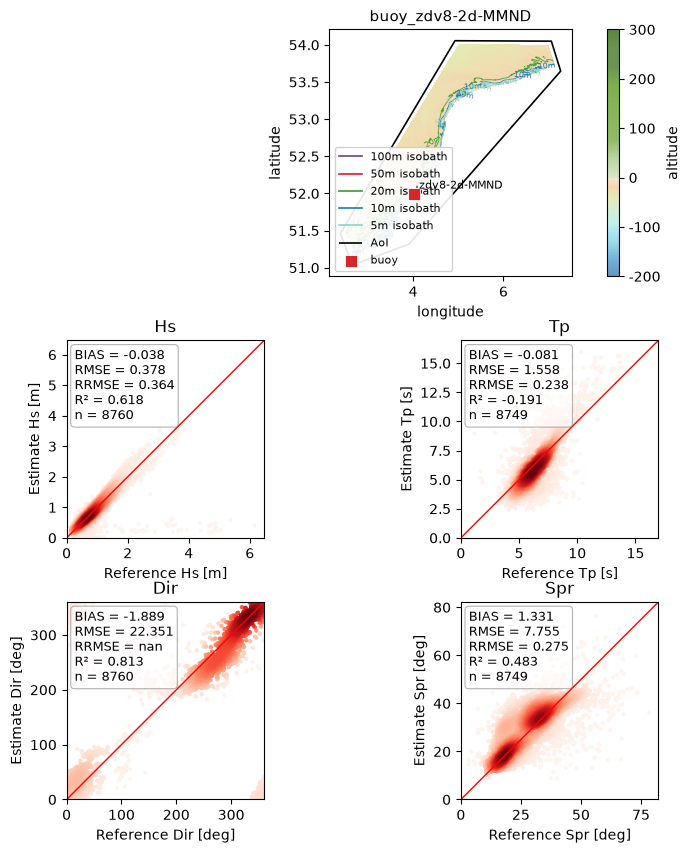

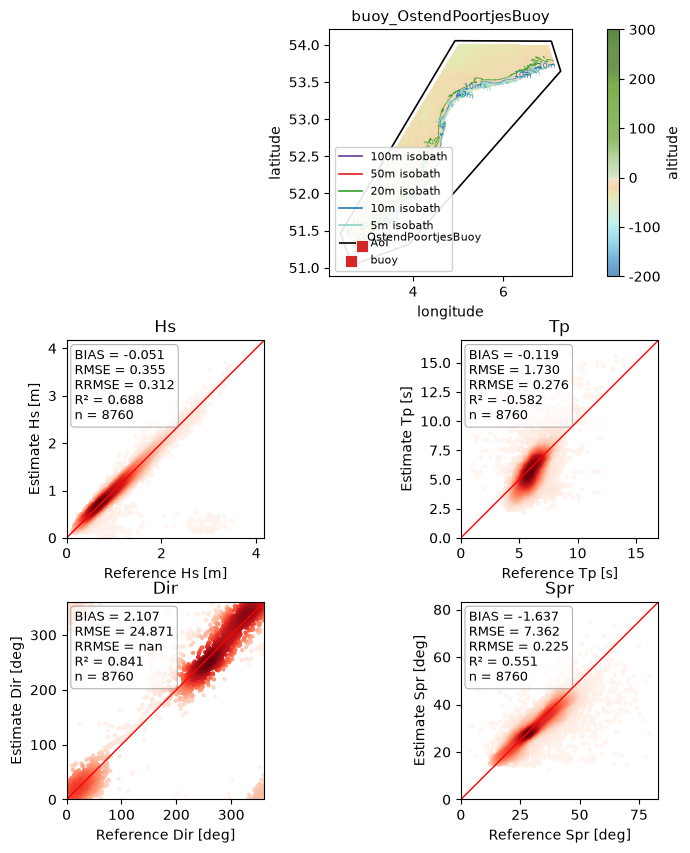

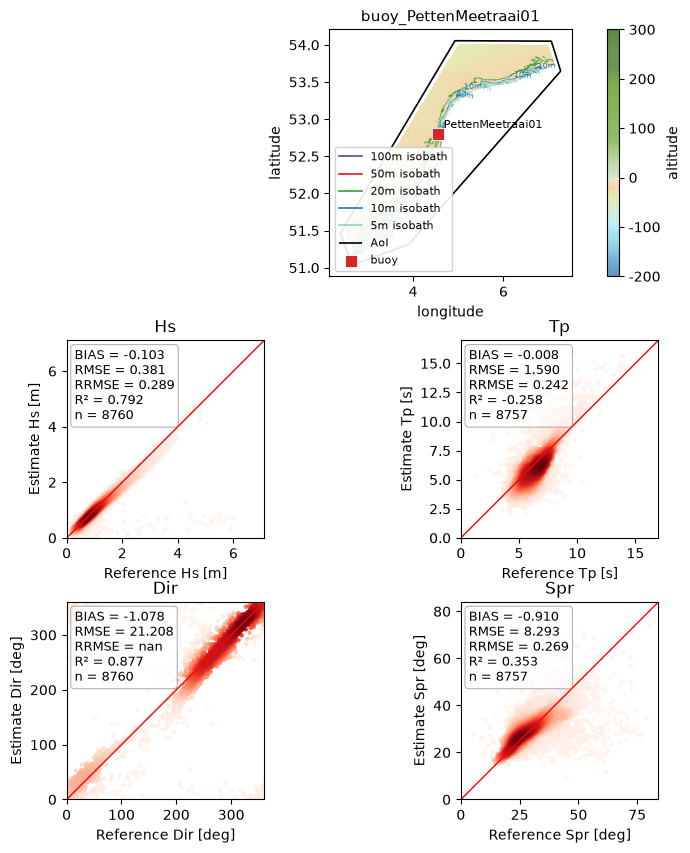

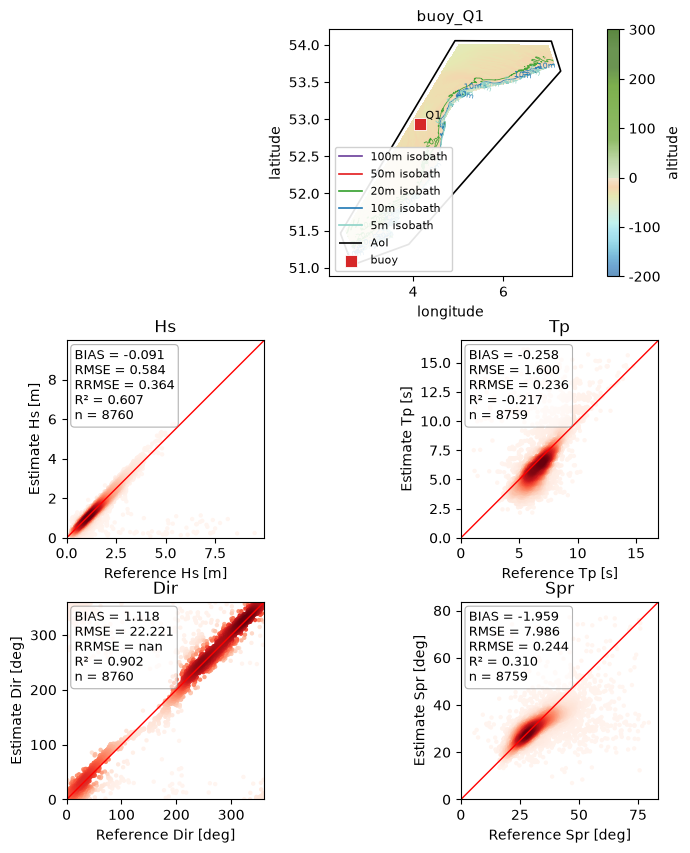

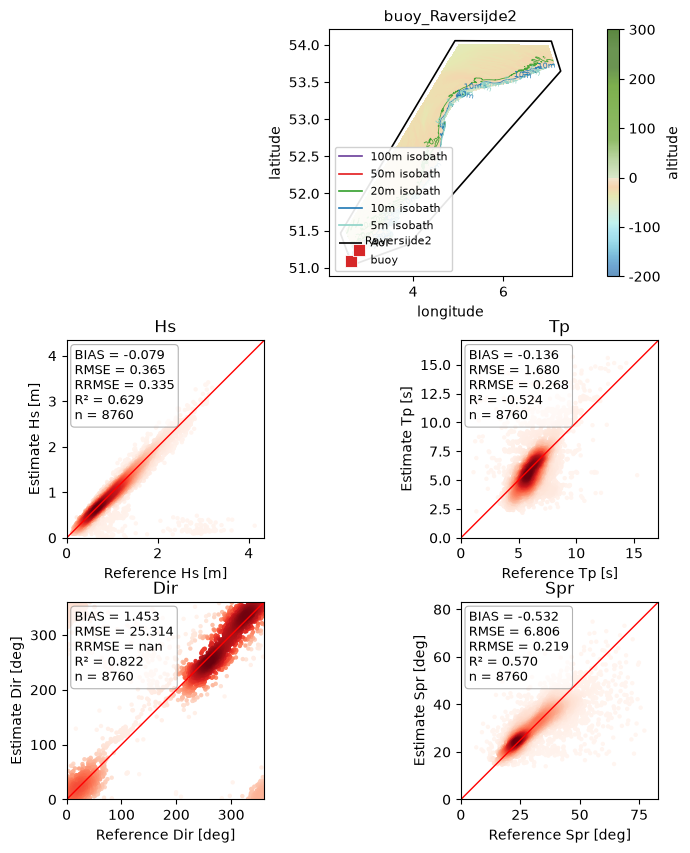

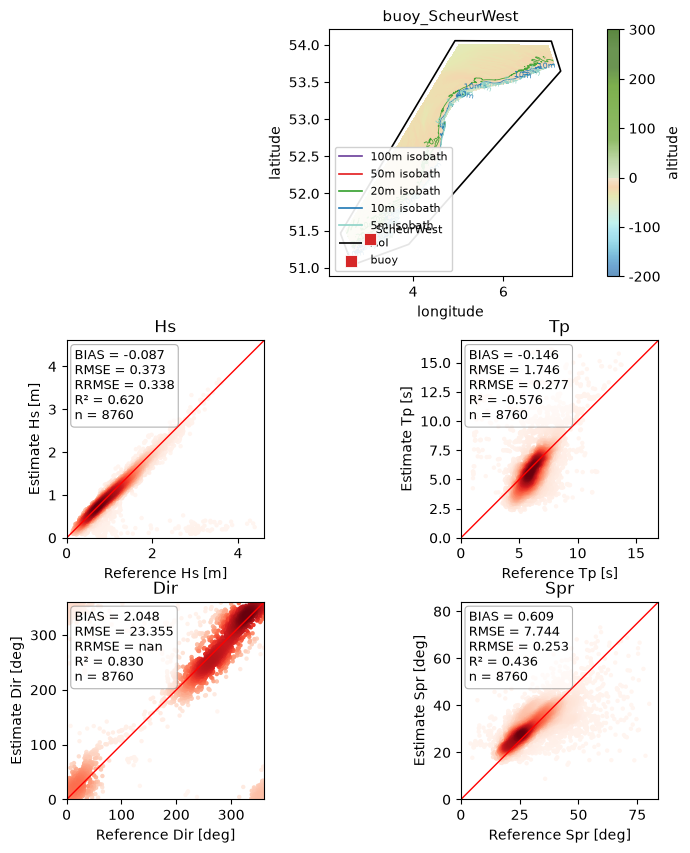

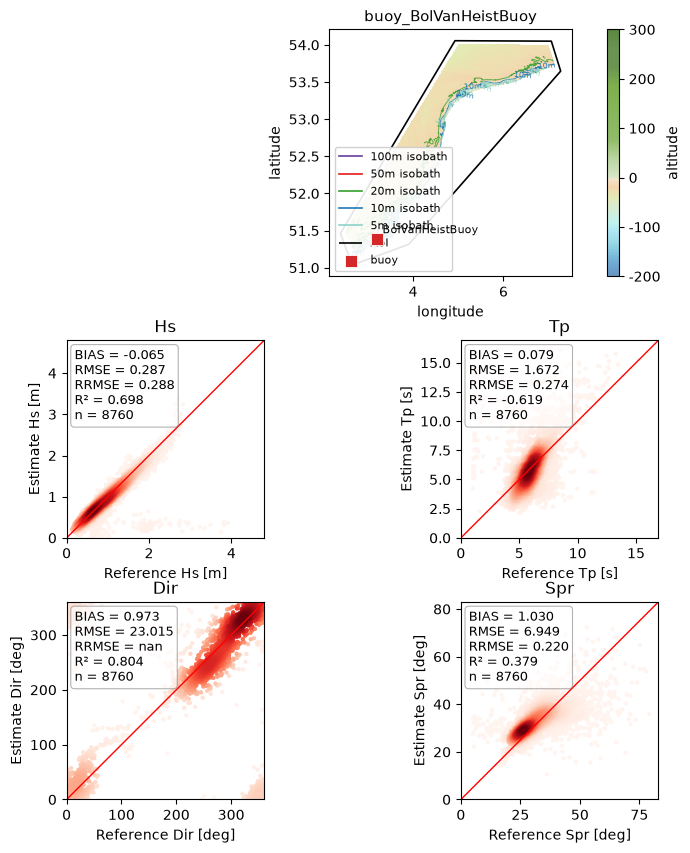

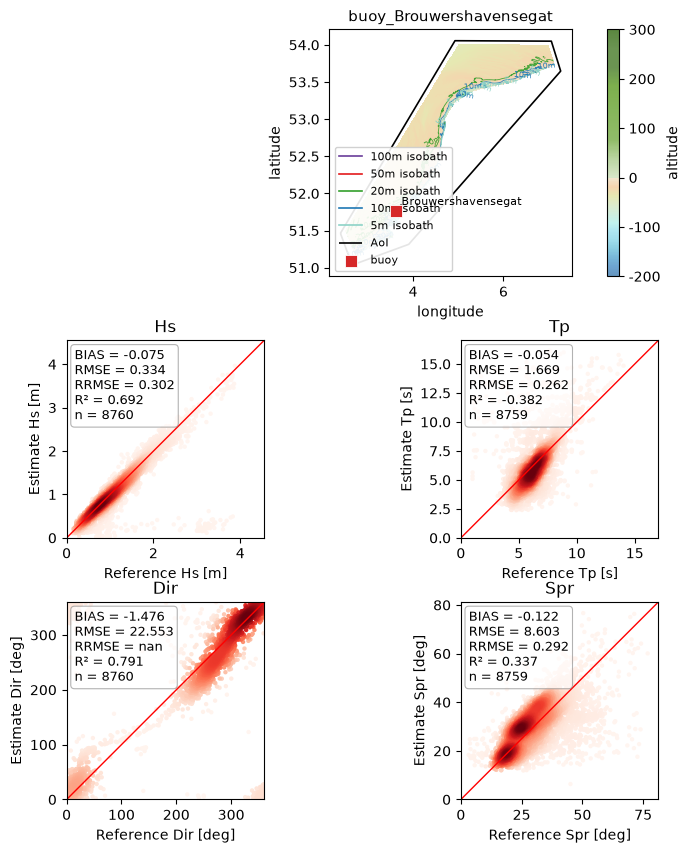

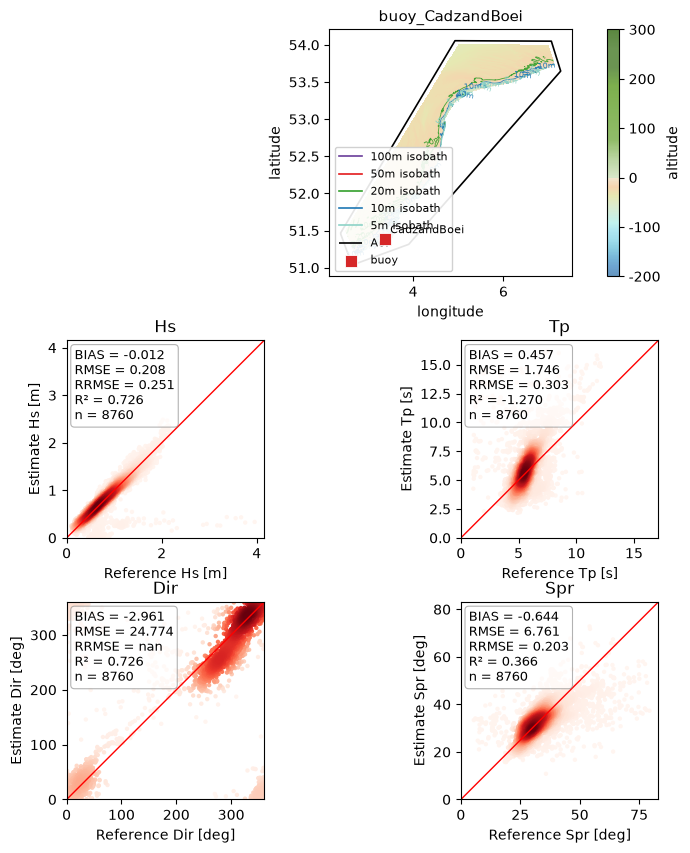

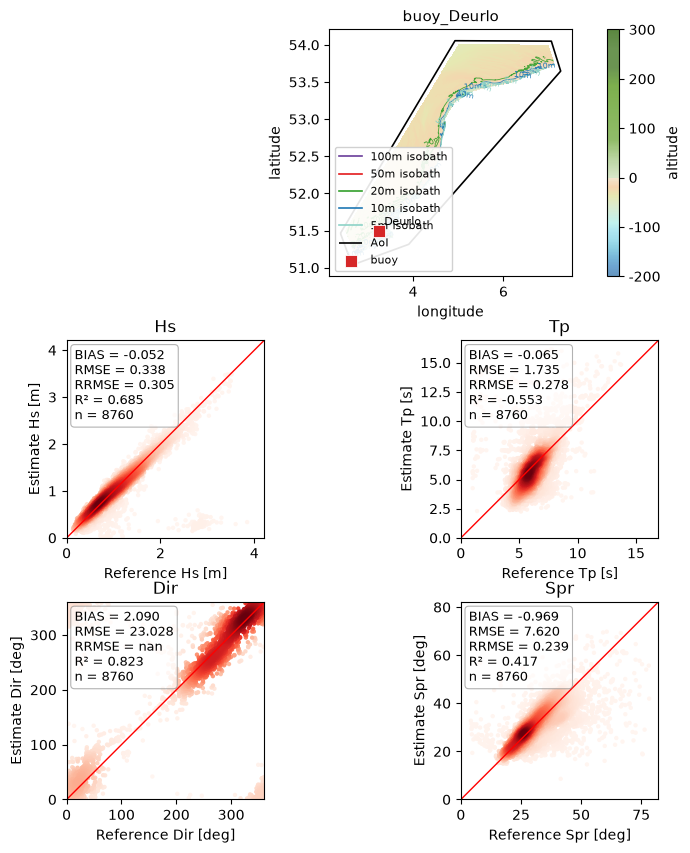

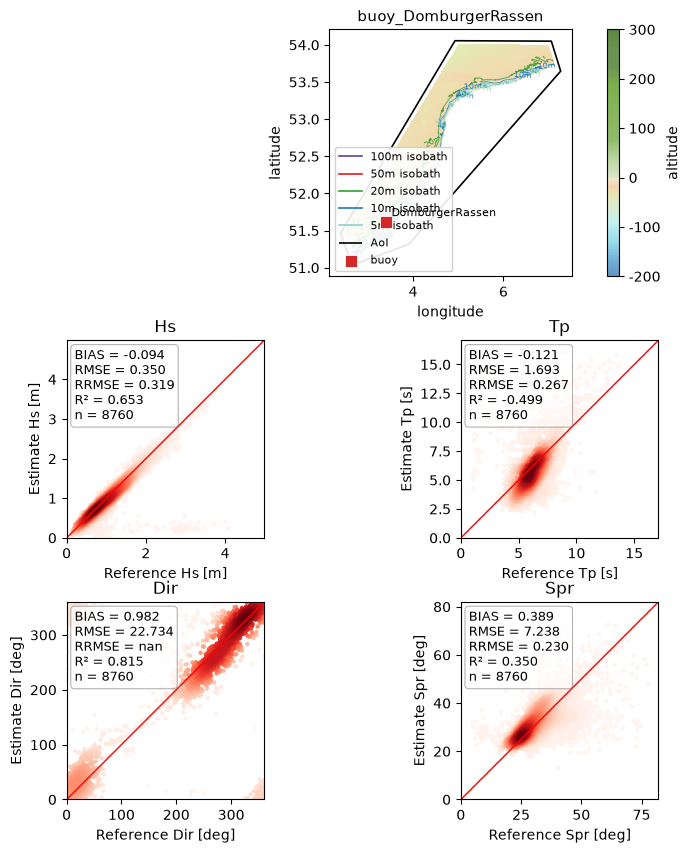

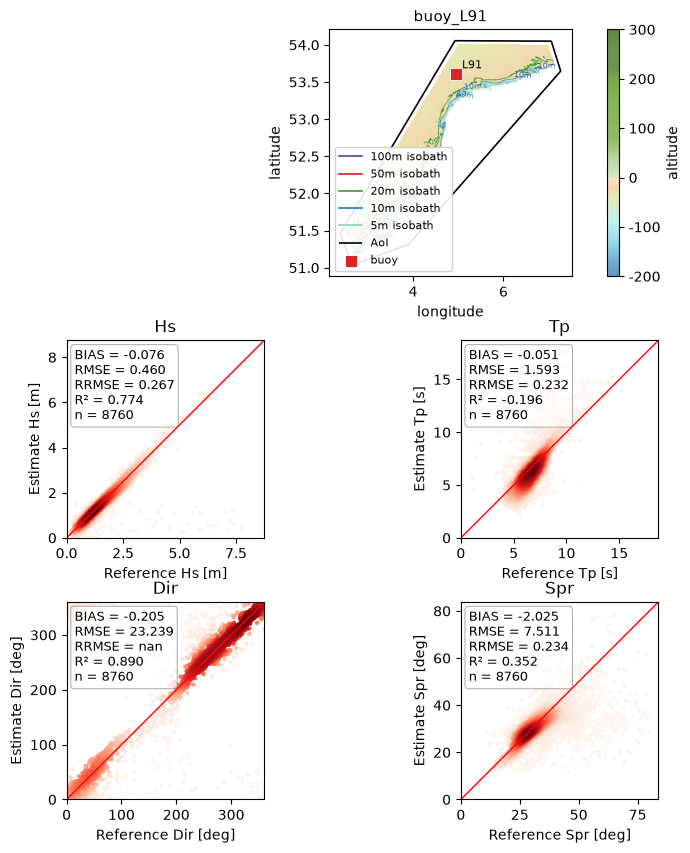

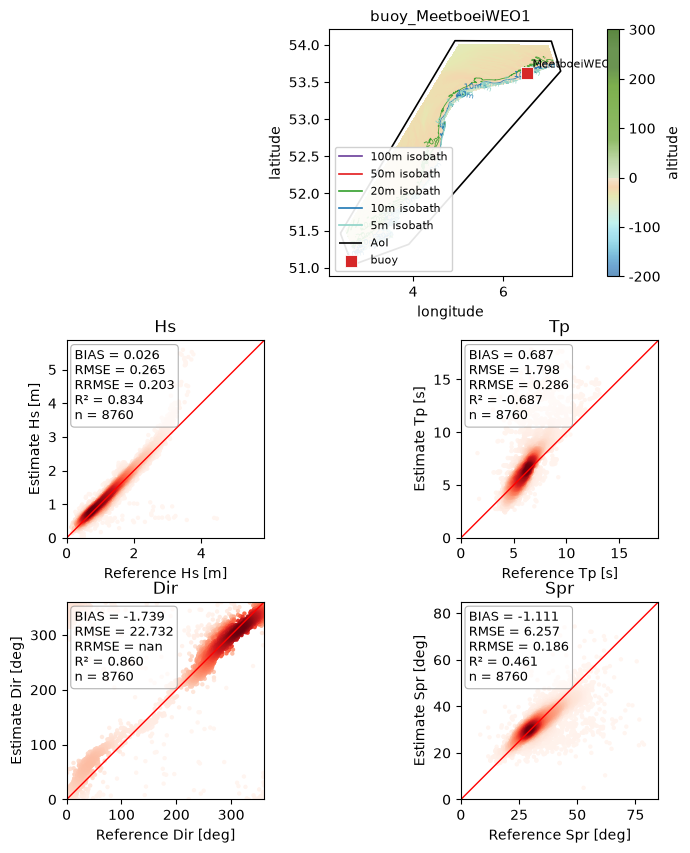

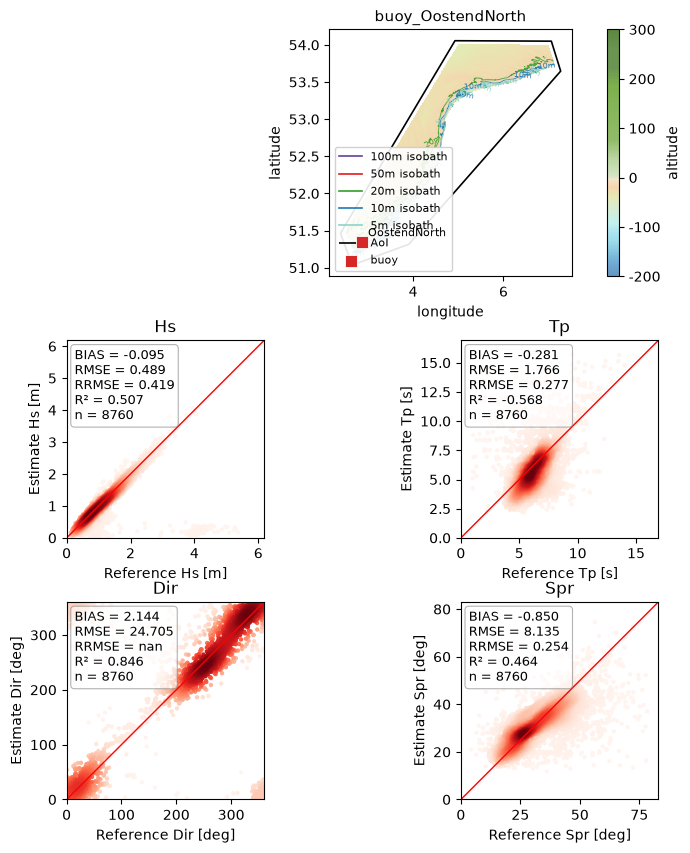

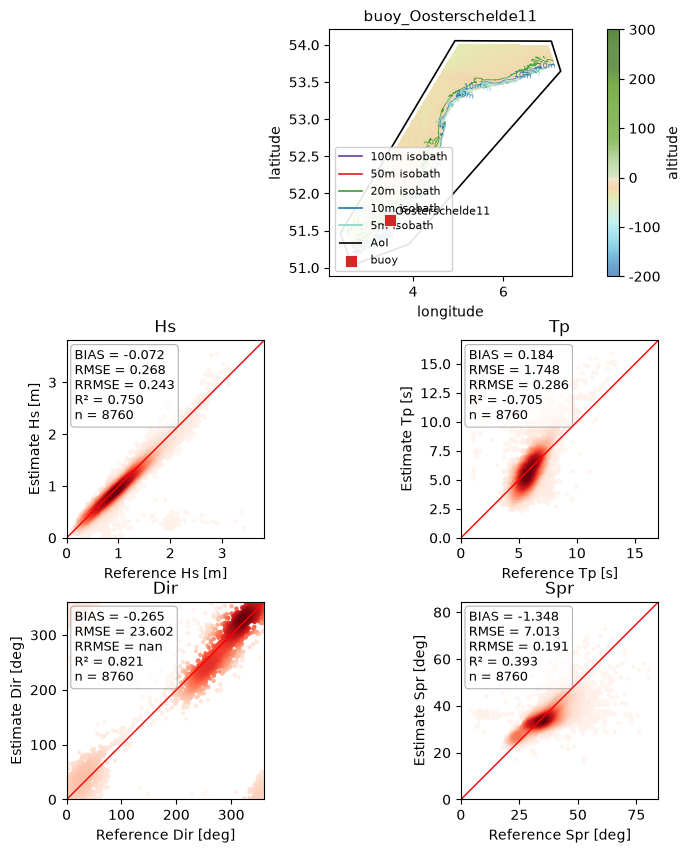

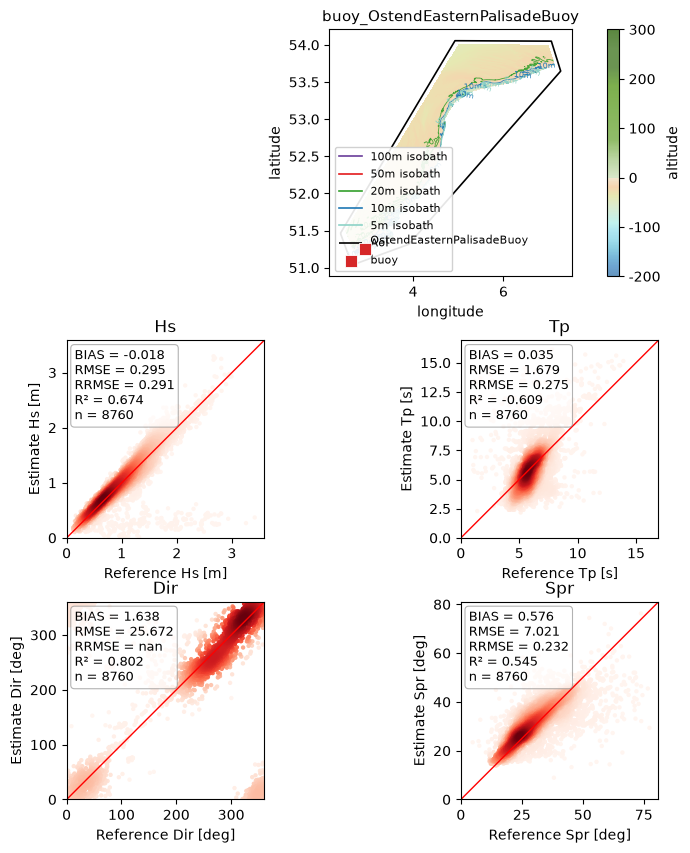

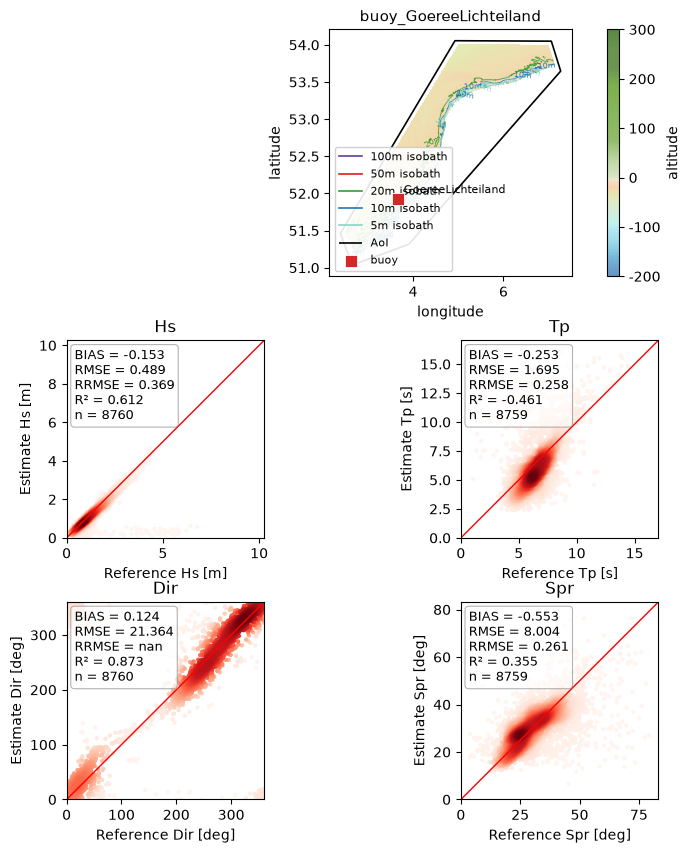

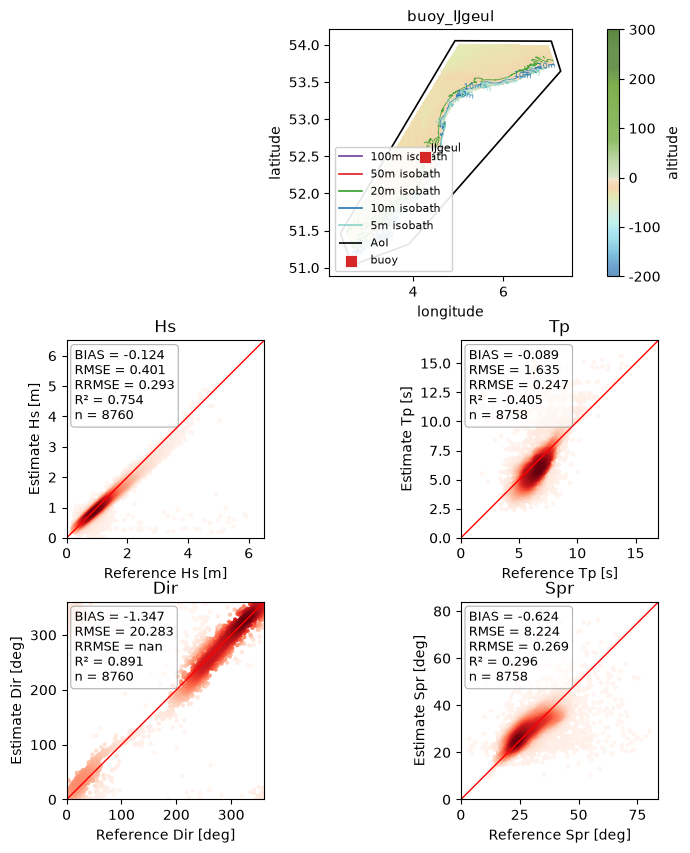

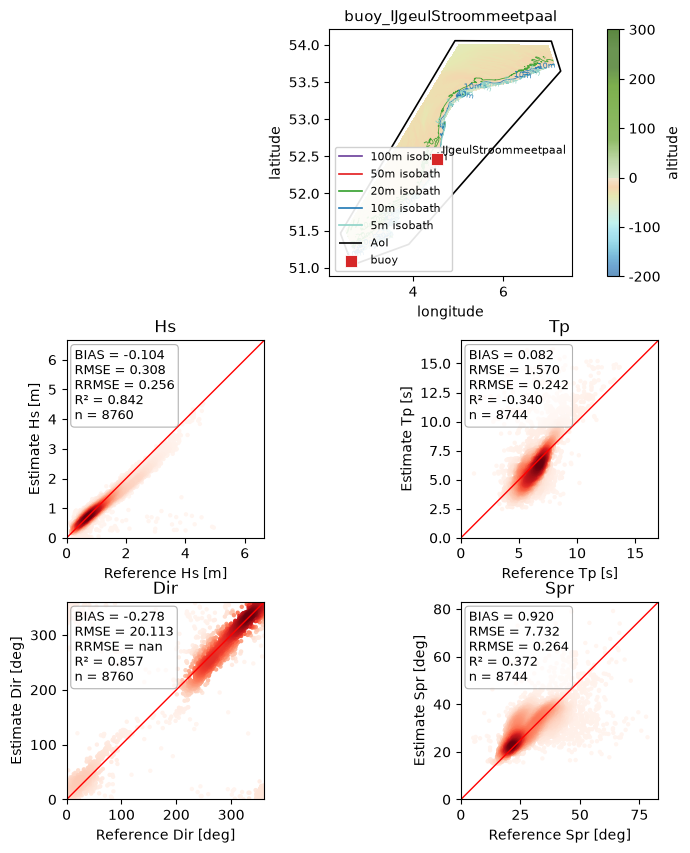

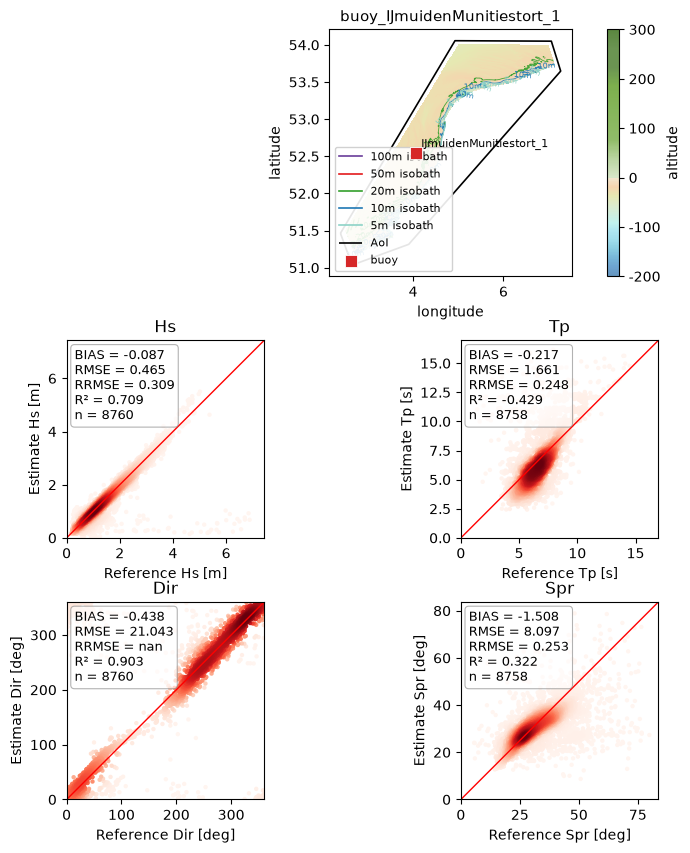

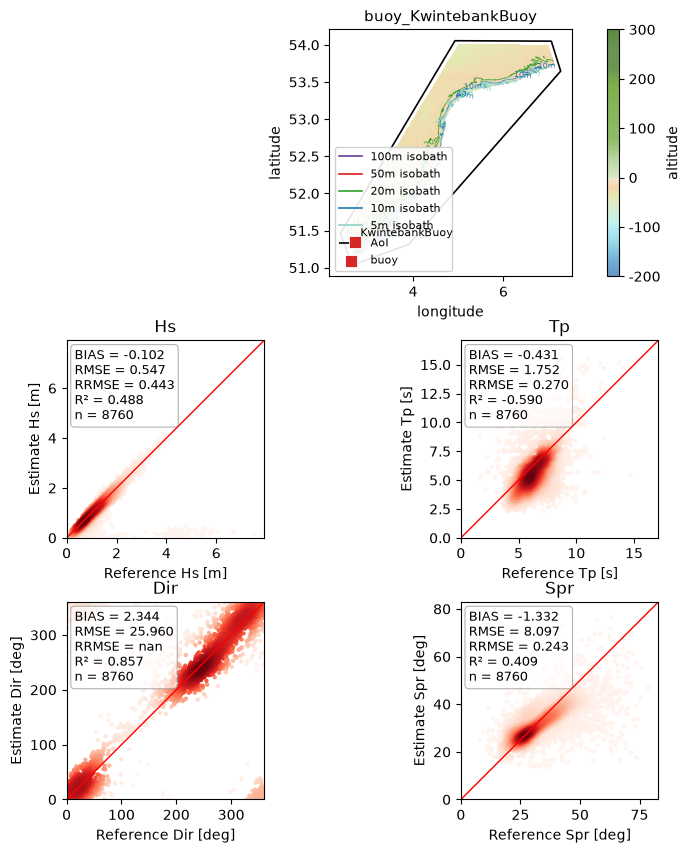

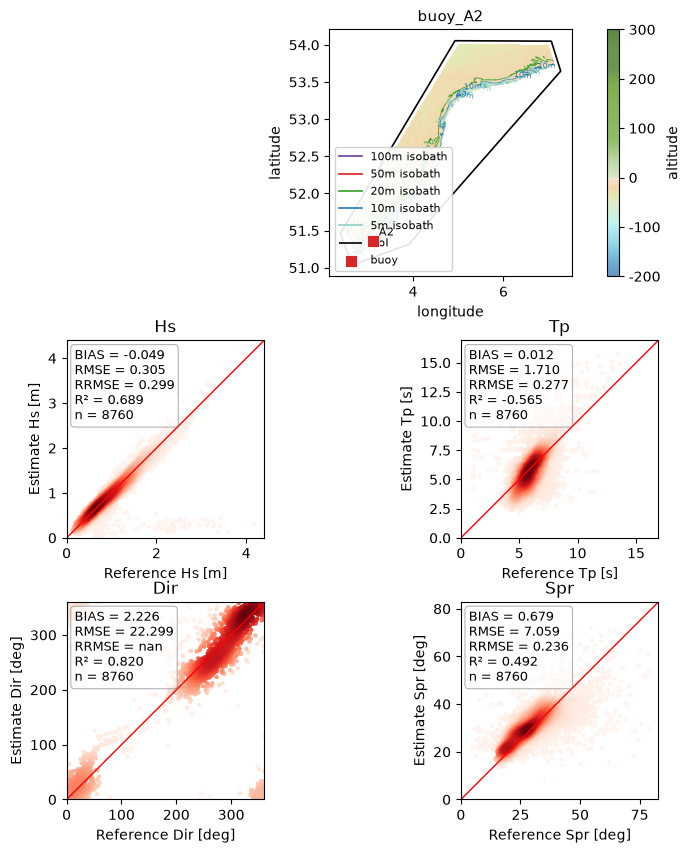

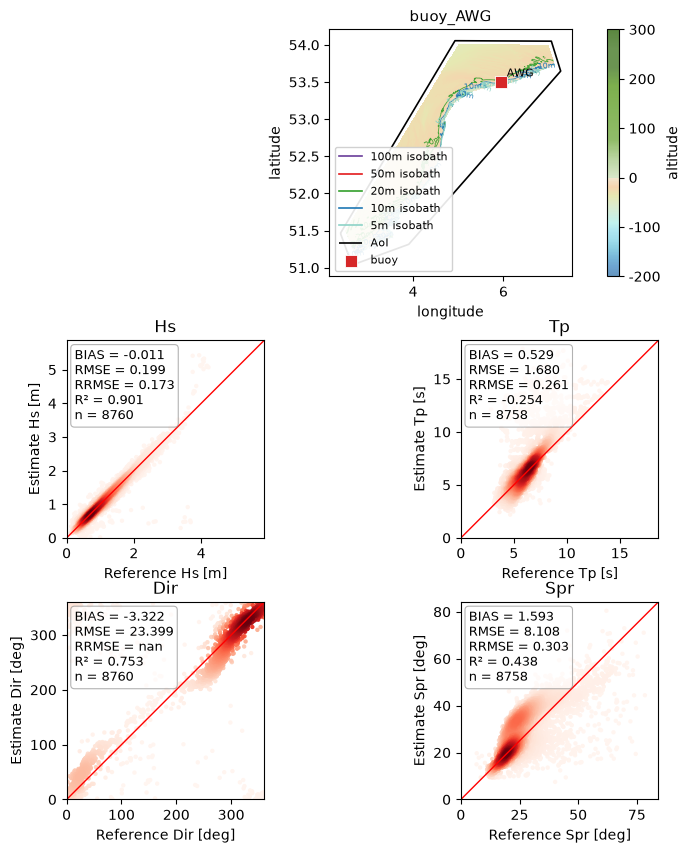

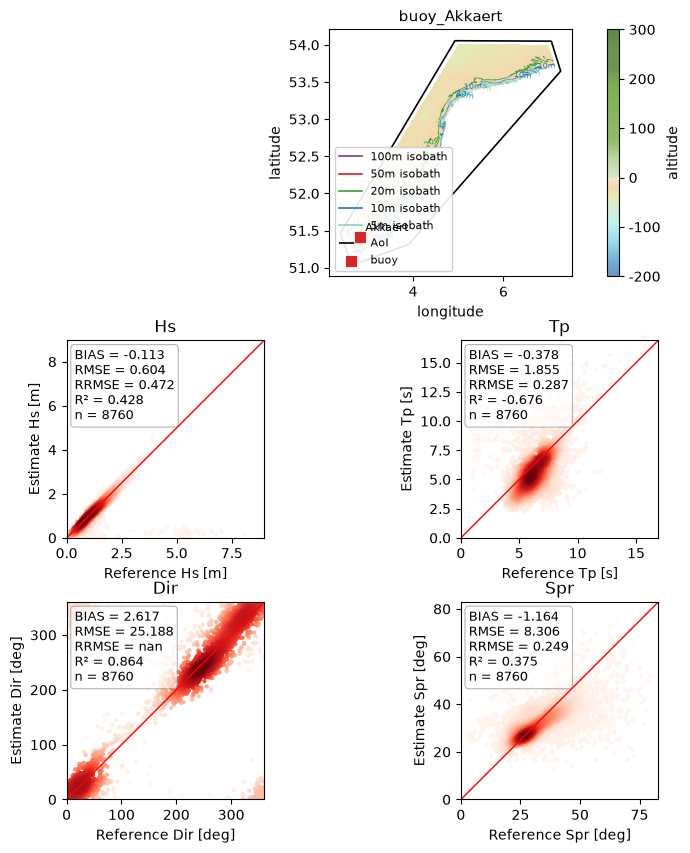

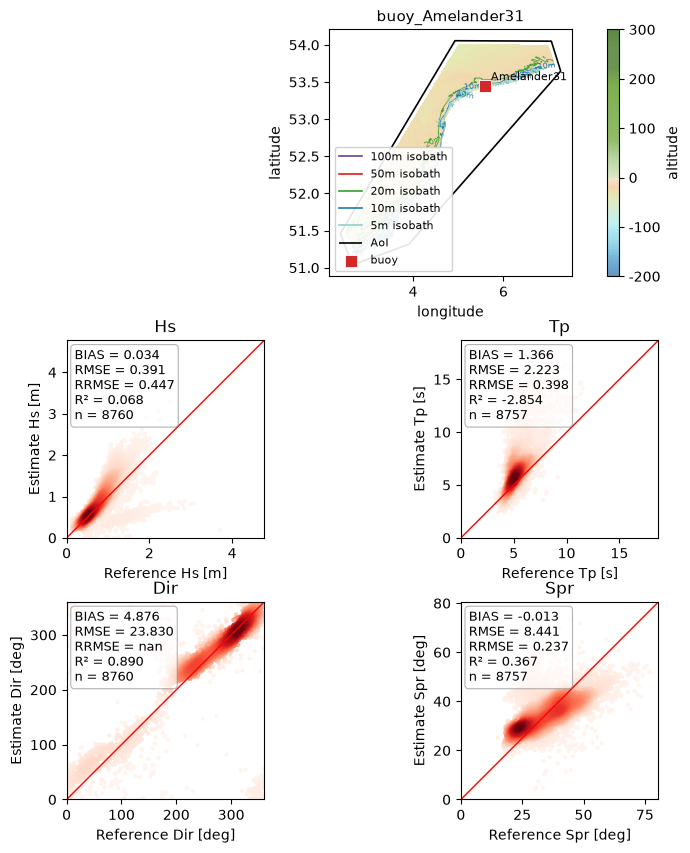

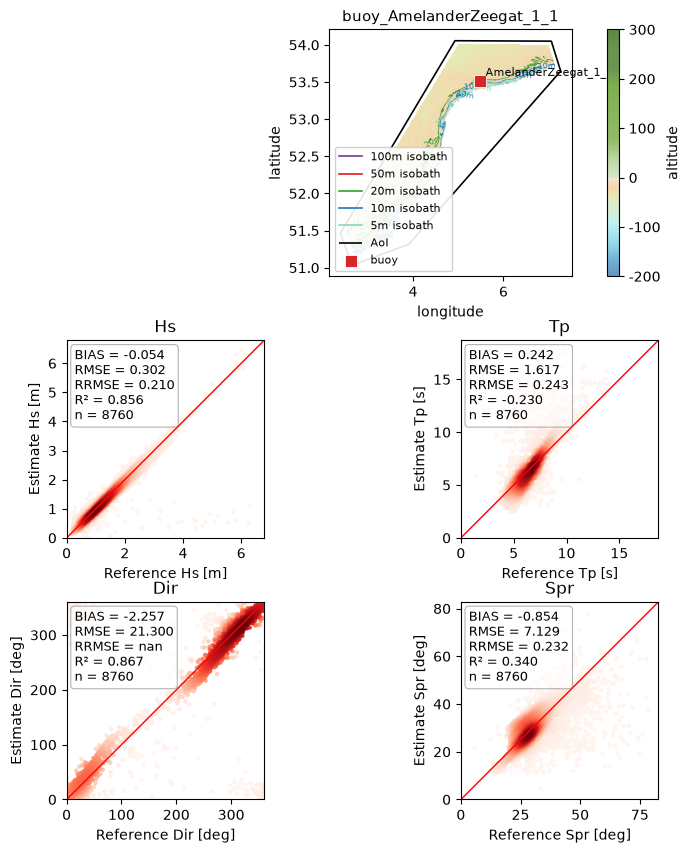

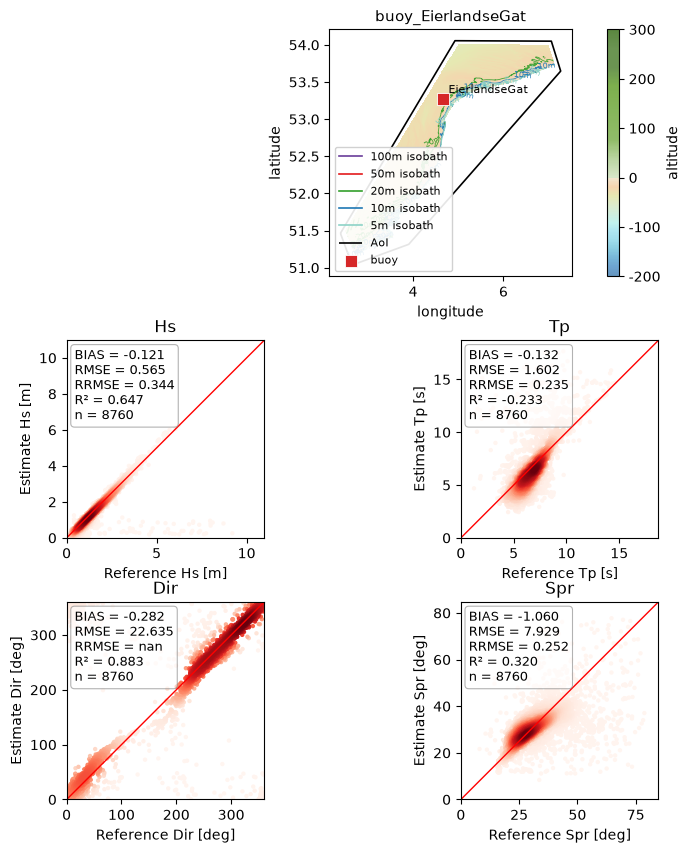

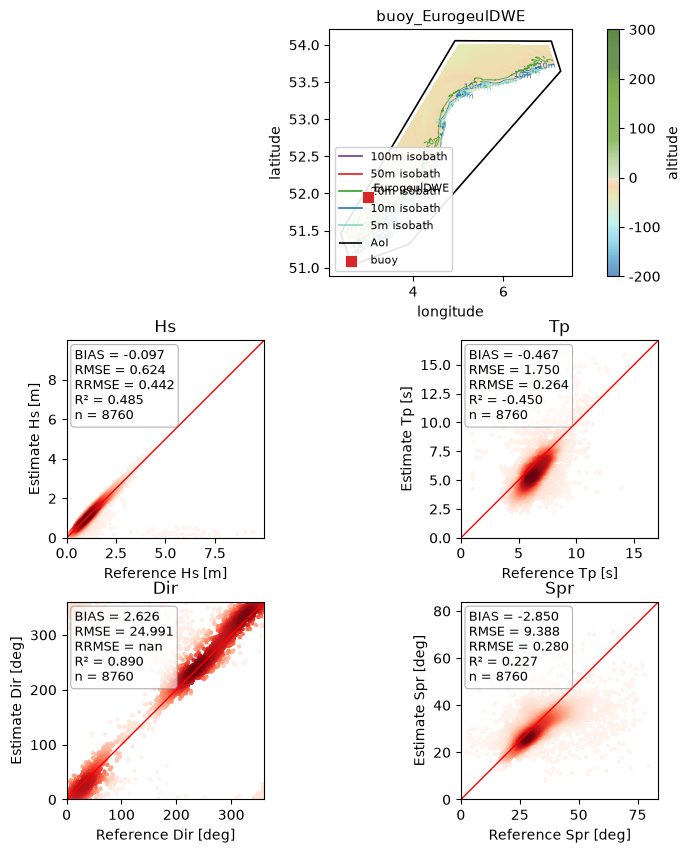

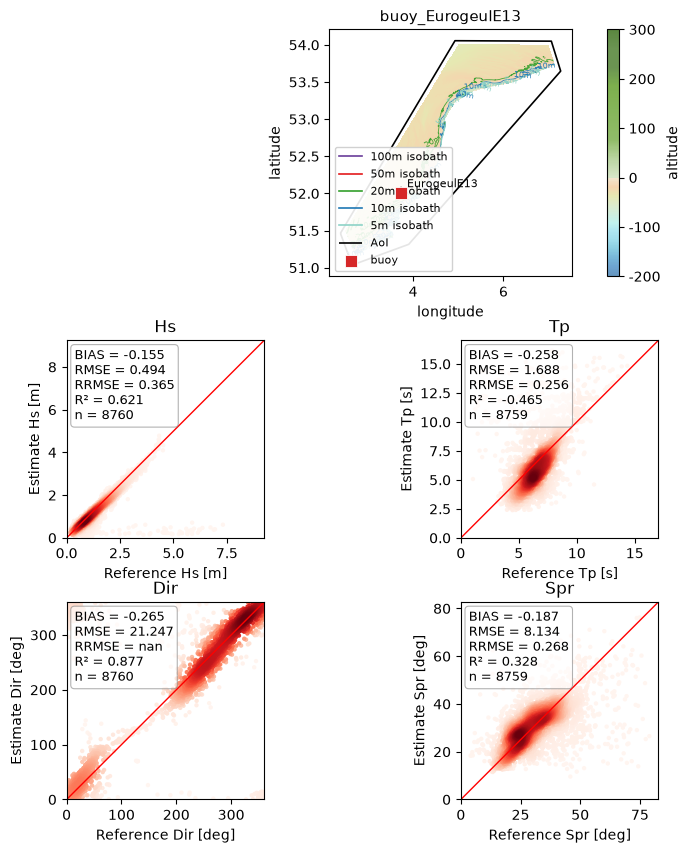

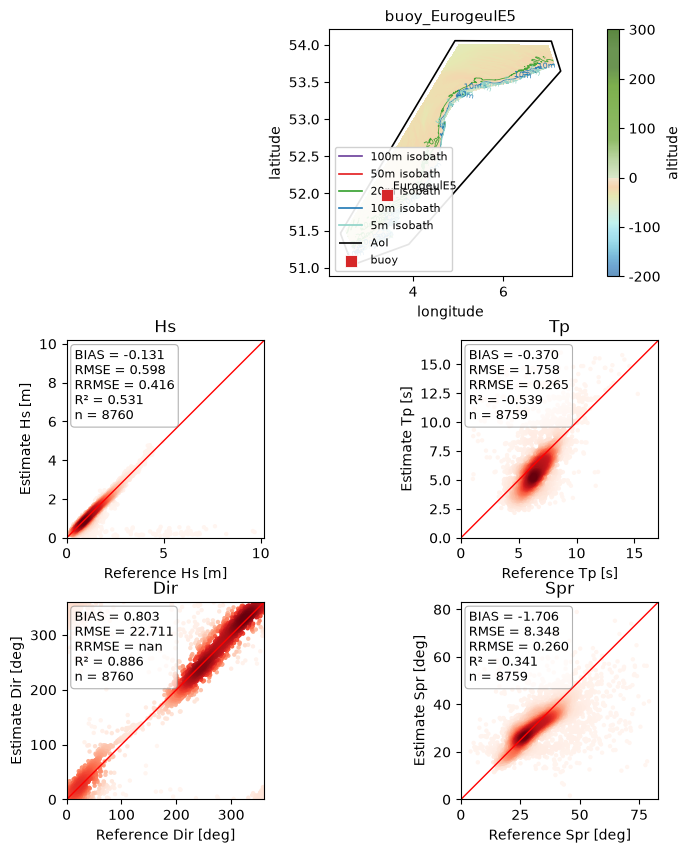

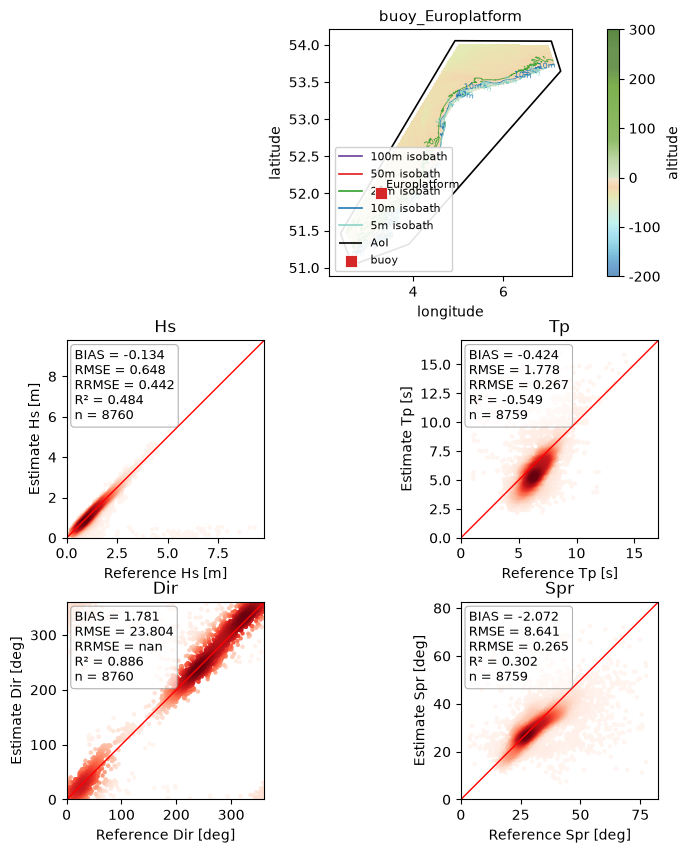

In [10]:
for fig in result.plot_all(variables=variables):
    plt.show()